# Task 2 – Data pipeline and deep-learning model (FruitSort)

**FCVG101 – FruitSort Vision Assistant · Task 2**

This notebook is the whole Task 2 workflow, one section per step:

| § | Step | Output |
|---|---|---|
| 1 | Ingestion of the Kaggle *Fruit Images for Object Detection* archive (CC0) | `../datasets/fruits/raw/`, `artifacts/import_log.csv` |
| 2 | Cleaning + grouped stratified split 70/15/15 | `../datasets/fruits/splits/`, `artifacts/data_manifest.csv`, `artifacts/rejected_images.csv` |
| 3 | Near-duplicate audit (perceptual hash) | `artifacts/near_duplicates.csv`, `results/near_duplicates.png` |
| 4 | Preprocessing and augmentation (`src/data_utils.py`) | figure of augmented samples |
| 5 | Model `FruitCNN` (`src/model.py`) | layer summary |
| 6 | Training with early stopping | `artifacts/model.pth`, `results/train_history.csv`, `results/learning_curves.png` |
| 7 | Evaluation on the locked test set | `results/test_metrics.json`, `results/confusion_matrix.png`, `results/test_predictions.csv` |
| 8 | Inference API used by Task 3 (`src/inference.py`) | prediction for one photo |

Run the cells in order with the working directory set to `task2/`. `src/` keeps the three modules that Task 3 imports
(`model.py`, `data_utils.py`, `inference.py`). The dataset lives in `../datasets/fruits/`.

**Switches** (first code cell): `KAGGLE_ARCHIVE` – path of the extracted Kaggle archive, only needed to rebuild
`raw/` from scratch; `RUN_TRAINING` – `True` retrains the CNN and overwrites `artifacts/model.pth`. With the defaults
the notebook reuses the submitted model, so the evaluation reproduces the numbers of the report.

In [1]:
from pathlib import Path
from collections import defaultdict, Counter
import csv, hashlib, json, random, re, shutil, sys, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

ROOT = Path.cwd()                                  # open the notebook from the task2/ folder
sys.path.insert(0, str(ROOT))
from src.model import FruitCNN
from src.data_utils import IMAGE_SIZE, MEAN, STD, SEED, make_transform
from src.inference import load_model, predict_pil

DATA = Path('..') / 'datasets' / 'fruits'          # relative, so the manifest stays portable
RAW, SPLITS = DATA / 'raw', DATA / 'splits'
ART, RES = Path('artifacts'), Path('results')
ART.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

KAGGLE_ARCHIVE = None      # e.g. r'C:\Users\<you>\Downloads\archive' to re-import the raw images
RUN_TRAINING = False       # True: train again and overwrite artifacts/model.pth

print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(), '| data:', DATA)

torch 2.14.1+cu130 | CUDA: True | data: ..\datasets\fruits


## 1. Ingestion – import the Kaggle images

The archive keeps every image in `train_zip/train` and `test_zip/test`, named `<class>_<n>.jpg`, with an `.xml` box file
for detection. This step:

- keeps only apple / banana / orange (by file-name prefix) and skips `mixed_*` photos, which have no single label;
- ignores the `.xml` files (the task here is classification);
- merges the original train and test folders – the split is redone in § 2;
- **copies** only, never modifies the source, and logs every decision to `artifacts/import_log.csv`;
- removes 20 images found by **visual inspection** (`EXCLUDE`): drawings, clipart, toys, large overlaid text, or a fruit of another class in the photo.

The file names carry no object/session information, so every image is its own group.

In [2]:
CLASSES = ('apple', 'banana', 'orange')
NAME_RE = re.compile(r'^([a-z]+)_(\d+)$', re.IGNORECASE)
IMG_EXT = {'.jpg', '.jpeg', '.png'}

# Ảnh loại bỏ sau khi kiểm tra bằng mắt (khóa: <split gốc>/<tên file không đuôi>).
EXCLUDE = {
    'test/apple_88': 'hình vẽ, không phải ảnh chụp',
    'train/apple_20': 'clipart',
    'train/apple_49': 'hình vẽ / đồ thủ công',
    'train/apple_11': 'chủ thể chính là mứt táo cuộn, không phải quả táo',
    'train/apple_63': 'chữ chèn lớn lên ảnh',
    'test/banana_92': 'hình vẽ',
    'test/banana_93': 'hình vector, có chữ "Banana"',
    'train/banana_1': 'đồ chơi hình quả chuối',
    'train/banana_11': 'hình vẽ',
    'train/banana_35': 'có quả đào (lớp khác) trong ảnh',
    'train/banana_46': 'hình vẽ',
    'train/banana_53': 'hình vẽ',
    'train/banana_57': 'hình minh họa',
    'train/banana_61': 'có quả táo (lớp khác) trong ảnh',
    'train/banana_67': 'đồ chơi gặm hình chuối',
    'train/banana_72': 'hình vẽ',
    'train/orange_11': 'hình vẽ',
    'train/orange_30': 'hình vẽ',
    'train/orange_35': 'hình vẽ',
    'train/orange_42': 'hình vẽ',
}


def import_kaggle(src: Path, dst: Path = RAW):
    """Copy the three classes from the extracted archive into dst/<class>/ and write the import log."""
    src = Path(src)
    if not src.is_dir():
        raise SystemExit(f'Không tìm thấy thư mục nguồn: {src}')
    for label in CLASSES:
        folder = dst / label
        if folder.exists() and any(folder.iterdir()):
            raise SystemExit(f'{folder} đã có ảnh. Xóa trước khi import để tránh lẫn dữ liệu.')
    log, counts = [], Counter()
    for path in sorted(src.rglob('*')):
        if not path.is_file() or path.suffix.lower() not in IMG_EXT:
            continue
        match = NAME_RE.match(path.stem)
        origin_split = path.parent.name  # 'train' hoặc 'test' của dataset gốc
        label = match.group(1).lower() if match else None
        if label not in CLASSES:
            counts['skipped:' + (label or 'unknown')] += 1
            log.append({'source': str(path), 'label': label or '', 'action': 'skipped',
                        'reason': 'không thuộc 3 lớp (mixed/khác)', 'saved_path': ''})
            continue
        reason = EXCLUDE.get(f'{origin_split}/{path.stem}')
        if reason:
            counts['excluded:' + label] += 1
            log.append({'source': str(path), 'label': label, 'action': 'excluded',
                        'reason': reason, 'saved_path': ''})
            continue
        target_dir = dst / label
        target_dir.mkdir(parents=True, exist_ok=True)
        target = target_dir / f'kaggle_{origin_split}_{path.stem}{path.suffix.lower()}'
        shutil.copy2(path, target)
        counts[label] += 1
        log.append({'source': str(path), 'label': label, 'action': 'copied',
                    'reason': '', 'saved_path': str(target)})
    with (ART / 'import_log.csv').open('w', newline='', encoding='utf-8-sig') as f:
        w = csv.DictWriter(f, fieldnames=['source', 'label', 'action', 'reason', 'saved_path'])
        w.writeheader()
        w.writerows(log)
    for label in CLASSES:
        print(f'{label:7s}: {counts[label]} ảnh (loại thủ công {counts["excluded:" + label]})')


if KAGGLE_ARCHIVE:
    import_kaggle(Path(KAGGLE_ARCHIVE))

# Summary of the import log (the raw images are already in ../datasets/fruits/raw)
log = pd.read_csv(ART / 'import_log.csv', encoding='utf-8-sig')
print(log.groupby(['action', 'label']).size().unstack(fill_value=0))
log[log.action == 'excluded'][['label', 'source', 'reason']].assign(source=lambda d: d.source.map(lambda s: Path(s).name))

label     apple  banana  mixed  orange
action                                
copied       89      80      0      86
excluded      5      11      0       4
skipped       0       0     25       0


,label,source,reason
11,apple,apple_88.jpg,"hình vẽ, không phải ảnh chụp"
34,banana,banana_92.jpg,hình vẽ
35,banana,banana_93.jpg,"hình vector, có chữ ""Banana"""
62,apple,apple_11.jpg,"chủ thể chính là mứt táo cuộn, không phải quả táo"
72,apple,apple_20.jpg,clipart
102,apple,apple_49.jpg,hình vẽ / đồ thủ công
118,apple,apple_63.jpg,chữ chèn lớn lên ảnh
135,banana,banana_1.jpg,đồ chơi hình quả chuối
137,banana,banana_11.jpg,hình vẽ
160,banana,banana_35.jpg,có quả đào (lớp khác) trong ảnh


## 2. Cleaning and grouped, stratified split

For every image in `raw/<class>/`:

1. **Integrity:** `PIL.verify()` and a full decode with EXIF orientation; unreadable/truncated files are rejected.
2. **Too small:** images under 32 × 32 px are rejected.
3. **Exact duplicates:** SHA-256 of the bytes; a copy inside one class is skipped, the same file in two classes stops the script (label error).
4. **Split by group** (`<group_id>__<view>.jpg`): all photos of one object go to the same split, 70/15/15 per class, seed 42.
   The output is rebuilt from scratch every time and is deterministic (sorted groups + fixed seed).

No offline augmentation is written to disk, so augmented copies of a photo can never leak into validation/test.

In [3]:
SPLIT_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}


def file_sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def group_name(path: Path) -> str:
    # Với file item001__cam2.jpg, cả item001__cam1 và item001__cam2 cùng group.
    return path.stem.split('__')[0]


def prepare_dataset(raw: Path = RAW, out: Path = SPLITS, seed: int = SEED):
    if not raw.exists() or not any(p.is_dir() for p in raw.iterdir()):
        raise SystemExit('Cần tạo raw/<class>/*.jpg trước (xem § 1).')
    image_groups = defaultdict(lambda: defaultdict(list))
    skipped, seen_hash = [], {}
    classes = sorted(p.name for p in raw.iterdir() if p.is_dir())
    for label in classes:
        for p in sorted((raw / label).rglob('*')):
            if not p.is_file() or p.suffix.lower() not in SPLIT_EXT:
                continue
            try:
                with Image.open(p) as im:
                    im.verify()
                with Image.open(p) as im:
                    if im.width < 32 or im.height < 32:
                        raise ValueError('Ảnh nhỏ hơn 32 px')
                    ImageOps.exif_transpose(im).convert('RGB').load()
                digest = file_sha256(p)
                if digest in seen_hash:
                    prev_path, prev_label = seen_hash[digest]
                    if prev_label != label:
                        raise ValueError(f'TRÙNG ảnh giữa 2 lớp: {prev_path}')
                    skipped.append((str(p), label, 'exact duplicate'))
                    continue
                seen_hash[digest] = (str(p), label)
                image_groups[label][group_name(p)].append((p, digest))
            except Exception as exc:
                skipped.append((str(p), label, str(exc)))
    if out.exists():                       # rebuilt from scratch to avoid leftovers of an earlier run
        for old in out.rglob('*'):         # delete files only: Windows may hold a handle on an open folder
            if old.is_file():
                old.unlink()
    rng = random.Random(seed)
    manifest = []
    for label in classes:
        groups = sorted(image_groups[label])
        if len(groups) < 3:
            raise SystemExit(f'Lớp {label}: cần ít nhất 3 group độc lập; hiện có {len(groups)}.')
        rng.shuffle(groups)
        n_test = max(1, round(len(groups) * 0.15))
        n_val = max(1, round(len(groups) * 0.15))
        if n_test + n_val >= len(groups):
            n_test, n_val = 1, 1
        partitions = {'test': groups[:n_test], 'val': groups[n_test:n_test + n_val],
                      'train': groups[n_test + n_val:]}
        for split, group_ids in partitions.items():
            folder = out / split / label
            folder.mkdir(parents=True, exist_ok=True)
            for group_id in group_ids:
                for p, digest in image_groups[label][group_id]:
                    target = folder / f'{digest[:10]}_{p.stem}.jpg'
                    with Image.open(p) as im:
                        ImageOps.exif_transpose(im).convert('RGB').save(target, quality=95, optimize=True)
                    manifest.append({'source': p.as_posix(), 'split': split, 'label': label, 'group_id': group_id,
                                     'sha256': digest, 'saved_path': target.as_posix()})
    with (ART / 'data_manifest.csv').open('w', newline='', encoding='utf-8-sig') as f:
        w = csv.DictWriter(f, fieldnames=['source', 'split', 'label', 'group_id', 'sha256', 'saved_path'])
        w.writeheader()
        w.writerows(manifest)
    with (ART / 'rejected_images.csv').open('w', newline='', encoding='utf-8-sig') as f:
        w = csv.writer(f)
        w.writerow(['source', 'label', 'reason'])
        w.writerows(skipped)
    return pd.DataFrame(manifest), skipped


manifest, rejected = prepare_dataset()
print('Valid images:', len(manifest), '| rejected:', len(rejected))
pd.crosstab(manifest.split, manifest.label, margins=True).loc[['train', 'val', 'test', 'All']]

C:\venvs\fcvg101\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Valid images: 255 | rejected: 0


label,apple,banana,orange,All
split,,,,
train,63,56,60,179
val,13,12,13,38
test,13,12,13,38
All,89,80,86,255


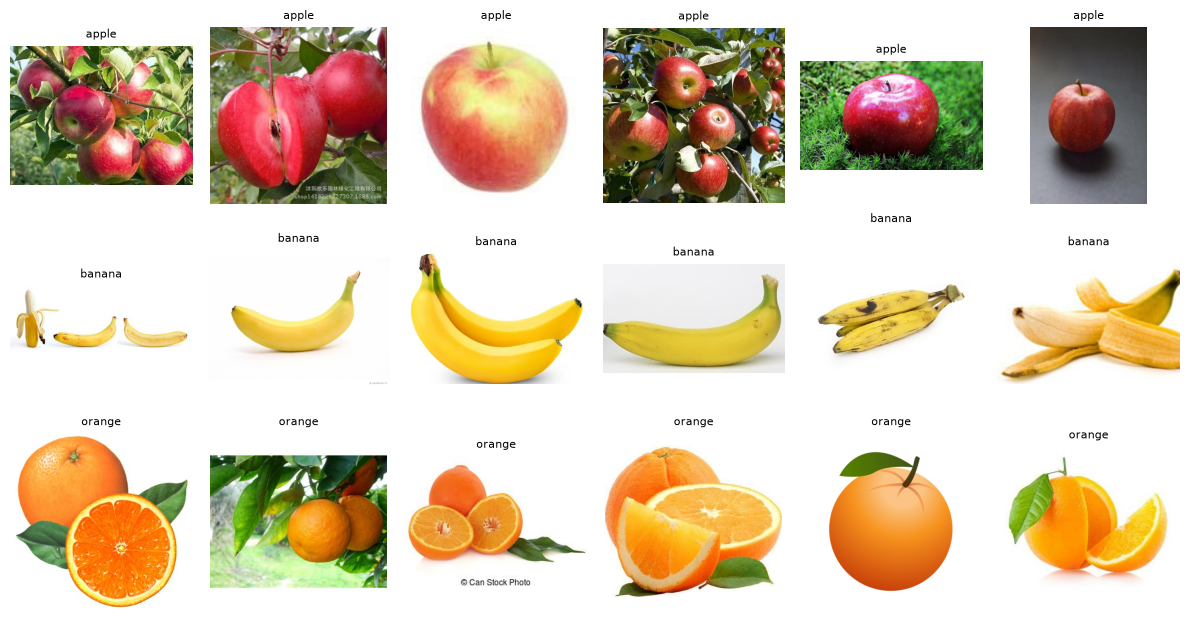

In [4]:
# A few training images per class
fig, axes = plt.subplots(3, 6, figsize=(12, 6.3))
for r, label in enumerate(['apple', 'banana', 'orange']):
    files = sorted((SPLITS / 'train' / label).glob('*.jpg'))[::9][:6]
    for ax, f in zip(axes[r], files):
        ax.imshow(Image.open(f)); ax.set_title(label, fontsize=8); ax.axis('off')
fig.tight_layout(); plt.show()

## 3. Near-duplicate audit (perceptual hash)

SHA-256 only catches byte-identical files. A resized, recompressed, lightly cropped or mirrored copy has a different
hash but nearly the same content – if one copy lands in train and the other in test, the test score is inflated.

1. Each image → grey 32 × 32 → 2-D DCT → keep the 8 × 8 low-frequency block → one bit per coefficient (above / below the median) → 64-bit hash. Low frequencies describe the overall light/dark layout, which survives resizing and recompression.
2. Hamming distance between hashes (0–64), also against the **mirrored** image.
3. Pairs with distance ≤ 14 are listed for **visual review** (cross-split pairs first). Nothing is deleted or moved.

On this dataset two crops of one original give d = 14 while two different photos have a median d = 28. The threshold
also catches pairs that only share a layout (one round fruit on white), so the list is a review aid, not a filter.

Images: 255 | pairs compared: 32385 | min distance: 8 | median: 28
Pairs with d <= 14: 73 | across splits: 29 | across classes: 33


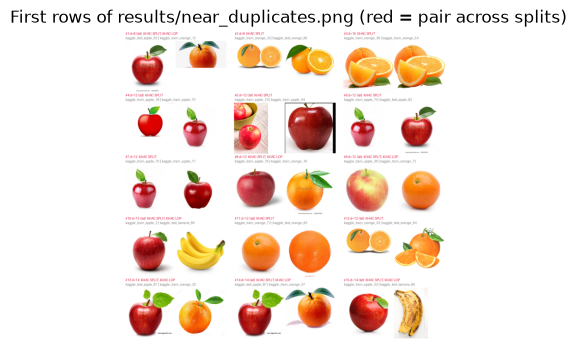

In [5]:
warnings.filterwarnings('ignore', message='Palette images with Transparency')
HASH_SIZE, HASH_IMG = 8, 32


def dct_matrix(n: int) -> np.ndarray:
    """Ma trận DCT-II trực chuẩn: dct2(X) = C @ X @ C.T"""
    k = np.arange(n)[:, None]
    i = np.arange(n)[None, :]
    c = np.cos(np.pi * (2 * i + 1) * k / (2 * n)) * np.sqrt(2 / n)
    c[0] /= np.sqrt(2)
    return c


DCT = dct_matrix(HASH_IMG)


def phash(gray: Image.Image) -> np.ndarray:
    pixels = np.asarray(gray.resize((HASH_IMG, HASH_IMG), Image.LANCZOS), dtype=np.float64)
    low = (DCT @ pixels @ DCT.T)[:HASH_SIZE, :HASH_SIZE]
    return (low > np.median(low)).flatten()


def load_hashes(path: Path):
    with Image.open(path) as im:
        gray = ImageOps.exif_transpose(im).convert('L')
        return phash(gray), phash(ImageOps.mirror(gray))


def find_pairs(rows, hashes, mirrored, threshold):
    h, hm = np.stack(hashes), np.stack(mirrored)            # (N, 64) bool
    d_same = (h[:, None, :] != h[None, :, :]).sum(-1)       # Hamming distance of every pair
    d_flip = (h[:, None, :] != hm[None, :, :]).sum(-1)
    dist = np.minimum(d_same, d_flip)
    pairs = []
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            if dist[i, j] <= threshold:
                a, b = rows[i], rows[j]
                pairs.append({'image_a': a['source'], 'image_b': b['source'], 'label_a': a['label'],
                              'label_b': b['label'], 'split_a': a['split'], 'split_b': b['split'],
                              'distance': int(dist[i, j]), 'mirrored': bool(d_flip[i, j] < d_same[i, j]),
                              'cross_split': a['split'] != b['split'], 'cross_class': a['label'] != b['label']})
    pairs.sort(key=lambda p: (not p['cross_split'], p['distance']))   # most dangerous first
    return pairs, dist


def save_grid(pairs, limit, out_png, thumb=160, per_row=3):
    """Contact sheet: each cell = one pair (A | B), numbered like the CSV rows."""
    shown = pairs[:limit]
    cell_w, cell_h = 2 * thumb + 24, thumb + 34
    sheet = Image.new('RGB', (per_row * cell_w, ((len(shown) + per_row - 1) // per_row) * cell_h), 'white')
    draw = ImageDraw.Draw(sheet)
    for k, p in enumerate(shown):
        x, y = (k % per_row) * cell_w, (k // per_row) * cell_h
        for j, key in enumerate(('a', 'b')):
            with Image.open(p[f'image_{key}']) as im:
                im = ImageOps.exif_transpose(im).convert('RGB')
                im.thumbnail((thumb, thumb))
                sheet.paste(im, (x + j * thumb, y + 32))
        flag = 'KHAC SPLIT' if p['cross_split'] else 'cung split'
        if p['cross_class']:
            flag += ', KHAC LOP'
        draw.text((x + 2, y + 2), f"#{k + 1} d={p['distance']}{' (lat)' if p['mirrored'] else ''}  {flag}",
                  fill='crimson' if p['cross_split'] else 'black')
        draw.text((x + 2, y + 16), f"{Path(p['image_a']).stem} | {Path(p['image_b']).stem}", fill='gray')
    sheet.save(out_png)
    return sheet


THRESHOLD = 14
rows = manifest.to_dict('records')
hashes, mirrored = zip(*(load_hashes(Path(r['source'])) for r in rows))
pairs, dist = find_pairs(rows, hashes, mirrored, THRESHOLD)
pd.DataFrame(pairs).to_csv(ART / 'near_duplicates.csv', index=False, encoding='utf-8-sig')
upper = dist[np.triu_indices(len(rows), k=1)]
print(f'Images: {len(rows)} | pairs compared: {len(upper)} | min distance: {upper.min()} | median: {int(np.median(upper))}')
print(f"Pairs with d <= {THRESHOLD}: {len(pairs)} | across splits: {sum(p['cross_split'] for p in pairs)} "
      f"| across classes: {sum(p['cross_class'] for p in pairs)}")
sheet = save_grid(pairs, 90, RES / 'near_duplicates.png')
plt.figure(figsize=(11, 4)); plt.imshow(sheet.crop((0, 0, sheet.width, 970))); plt.axis('off')
plt.title('First rows of results/near_duplicates.png (red = pair across splits)'); plt.show()

## 4. Preprocessing and augmentation

`src/data_utils.make_transform` is the single definition used by training, validation, test **and** the Task 3 app:
resize to 128 × 128, `ToTensor`, normalise with mean = std = 0.5 (→ [−1, 1]). Training only adds random rotation ±12°,
horizontal flip (p = 0.5) and brightness/contrast jitter ±15 % – the variation of a hand-held phone photo. Vertical
flips and hue changes are not used because they create unrealistic fruit.

"""Định nghĩa tiền xử lý thống nhất giữa train, validation, test và inference."""
from torchvision import transforms

IMAGE_SIZE = 128
MEAN = [0.5, 0.5, 0.5]
STD = [0.5, 0.5, 0.5]
SEED = 42


def make_transform(train: bool = False, size: int = IMAGE_SIZE,
                   mean=MEAN, std=STD):
    operations = [transforms.Resize((size, size))]
    if train:
        operations.extend([
            transforms.RandomRotation(12),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.15, contrast=0.15),
        ])
    operations.extend([
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    return transforms.Compose(operations)



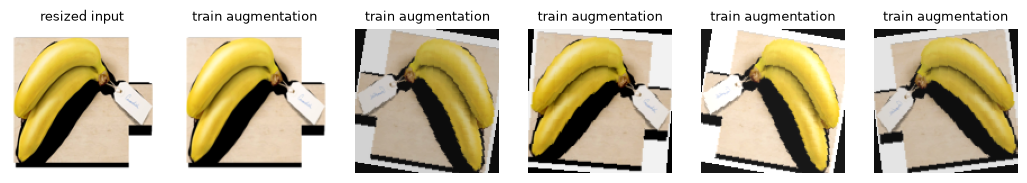

In [6]:
import inspect, src.data_utils
print(inspect.getsource(src.data_utils))

torch.manual_seed(0)
sample = Image.open(sorted((SPLITS / 'train' / 'banana').glob('*.jpg'))[3]).convert('RGB')
aug = make_transform(train=True)
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
axes[0].imshow(sample.resize((IMAGE_SIZE, IMAGE_SIZE))); axes[0].set_title('resized input', fontsize=9)
for ax in axes[1:]:
    x = aug(sample)
    ax.imshow((x.permute(1, 2, 0).numpy() * 0.5 + 0.5).clip(0, 1)); ax.set_title('train augmentation', fontsize=9)
for ax in axes: ax.axis('off')
plt.show()

## 5. Model: FruitCNN

Three Conv 3×3 → ReLU (→ MaxPool) blocks, global average pooling and one linear layer that returns logits
(`CrossEntropyLoss` applies log-softmax itself). About 24 k parameters – small enough for 179 training images,
and global pooling keeps the last feature maps usable for Grad-CAM in Task 3.

In [7]:
import src.model
print(inspect.getsource(src.model))
net = FruitCNN(n_classes=3)
x = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE)
rows = []
for layer in list(net.features) + [nn.Flatten(), net.head]:
    x = layer(x)
    rows.append({'layer': layer.__class__.__name__, 'output shape': tuple(x.shape[1:]),
                 'parameters': sum(p.numel() for p in layer.parameters())})
summary = pd.DataFrame(rows)
print('Total parameters:', summary.parameters.sum())
summary

"""CNN nhỏ cho bài toán phân loại ảnh RGB (ví dụ táo/cam/chuối)."""
import torch
from torch import nn


class FruitCNN(nn.Module):
    def __init__(self, n_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.head = nn.Linear(64, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(x).flatten(1))  # logits; không dùng softmax khi train

Total parameters: 23779


,layer,output shape,parameters
0,Conv2d,"(16, 128, 128)",448
1,ReLU,"(16, 128, 128)",0
2,MaxPool2d,"(16, 64, 64)",0
3,Conv2d,"(32, 64, 64)",4640
4,ReLU,"(32, 64, 64)",0
5,MaxPool2d,"(32, 32, 32)",0
6,Conv2d,"(64, 32, 32)",18496
7,ReLU,"(64, 32, 32)",0
8,AdaptiveAvgPool2d,"(64, 1, 1)",0
9,Flatten,"(64,)",0


## 6. Training

Adam (lr 1e-3), batch 32, cross-entropy, up to 200 epochs with **early stopping** (patience 20) on the validation loss;
the checkpoint with the lowest validation loss is saved together with the preprocessing metadata, so the model can be
used without this notebook. Seeds are fixed for Python, NumPy and PyTorch.

With `RUN_TRAINING = False` the cell shows the history of the submitted model instead of retraining
(GPU training is not bit-exact, so a new run gives slightly different numbers).

{'class_to_idx': {'apple': 0, 'banana': 1, 'orange': 2}, 'image_size': 128, 'mean': [0.5, 0.5, 0.5], 'std': [0.5, 0.5, 0.5], 'architecture': 'FruitCNN_3Conv_GAP', 'best_epoch': 54, 'best_val_loss': 0.30157088056990977, 'best_val_accuracy': 0.9473684210526315, 'seed': 42}


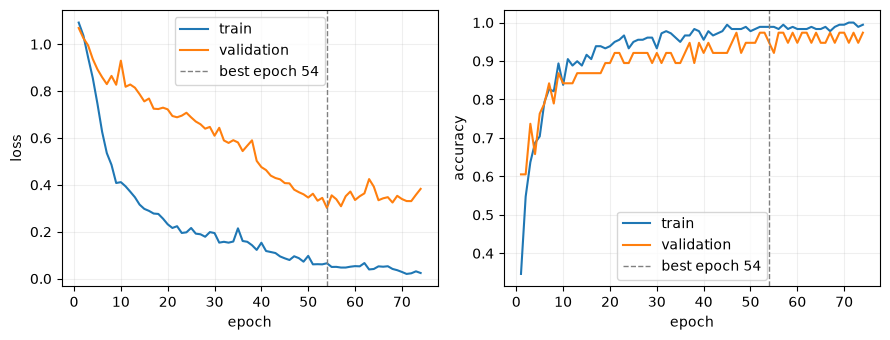

In [8]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def run_epoch(model, loader, criterion, optimizer, device):
    training = optimizer is not None
    model.train(training)
    total_loss, total_right, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.size(0)
            total_right += (logits.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    if total == 0:
        raise RuntimeError('DataLoader rỗng. Kiểm tra split và ảnh hợp lệ.')
    return total_loss / total, total_right / total


def train(epochs=200, batch_size=32, lr=1e-3, patience=20):
    set_seed(SEED)
    tr = ImageFolder(SPLITS / 'train', transform=make_transform(train=True))
    va = ImageFolder(SPLITS / 'val', transform=make_transform(train=False))
    if tr.class_to_idx != va.class_to_idx:
        raise RuntimeError('Class mapping không nhất quán giữa train / val.')
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(va, batch_size=batch_size, shuffle=False, num_workers=0)
    net = FruitCNN(n_classes=len(tr.classes)).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optim = torch.optim.Adam(net.parameters(), lr=lr)
    (ART / 'classes.json').write_text(json.dumps(tr.class_to_idx, indent=2), encoding='utf-8')
    best_loss, best_epoch, history = float('inf'), 0, []
    print('device:', device, '| train/val:', len(tr), len(va))
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(net, loader, loss_fn, optim, device)
        va_loss, va_acc = run_epoch(net, val_loader, loss_fn, None, device)
        history.append({'epoch': ep, 'train_loss': tr_loss, 'train_accuracy': tr_acc,
                        'val_loss': va_loss, 'val_accuracy': va_acc})
        if va_loss < best_loss:
            best_loss, best_epoch = va_loss, ep
            torch.save({'model_state': net.state_dict(), 'class_to_idx': tr.class_to_idx,
                        'image_size': IMAGE_SIZE, 'mean': MEAN, 'std': STD,
                        'architecture': 'FruitCNN_3Conv_GAP', 'best_epoch': ep,
                        'best_val_loss': va_loss, 'best_val_accuracy': va_acc, 'seed': SEED}, ART / 'model.pth')
        print(f'epoch {ep:02d} train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} val_loss={va_loss:.4f} val_acc={va_acc:.3f}')
        if patience and ep - best_epoch >= patience:
            print(f'Early stopping: val loss không giảm trong {patience} epoch kể từ epoch {best_epoch}.')
            break
    pd.DataFrame(history).to_csv(RES / 'train_history.csv', index=False)
    return best_epoch


if RUN_TRAINING:
    train(epochs=200, batch_size=32, lr=1e-3, patience=20)

history = pd.read_csv(RES / 'train_history.csv')
ckpt = torch.load(ART / 'model.pth', map_location='cpu', weights_only=True)
best_epoch = ckpt['best_epoch']
print({k: v for k, v in ckpt.items() if k != 'model_state'})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, suffix in zip(axes, ['loss', 'accuracy']):
    ax.plot(history.epoch, history['train_' + suffix], label='train')
    ax.plot(history.epoch, history['val_' + suffix], label='validation')
    ax.axvline(best_epoch, color='gray', ls='--', lw=1, label=f'best epoch {best_epoch}')
    ax.set_xlabel('epoch'); ax.set_ylabel(suffix); ax.grid(alpha=.2); ax.legend()
fig.tight_layout()
if RUN_TRAINING:
    fig.savefig(RES / 'learning_curves.png', dpi=150)
plt.show()

## 7. Evaluation on the locked test set

The checkpoint is chosen by validation loss only; the 38 test images are used **once**, here. The class-to-index
mapping of the test folder must equal the checkpoint's. Metrics: accuracy, macro-F1, per-class precision/recall/F1,
confusion matrix, and every prediction in `results/test_predictions.csv`.

TEST n=38 | accuracy=0.9737 | macro_F1=0.9732

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        13
      banana       1.00      0.92      0.96        12
      orange       0.93      1.00      0.96        13

    accuracy                           0.97        38
   macro avg       0.98      0.97      0.97        38
weighted avg       0.98      0.97      0.97        38



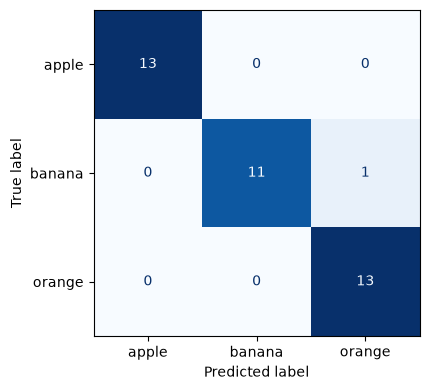

Accuracy 37/38 = 97.4%, 95 % Wilson CI 86.5% – 99.5%


,file,actual,predicted,correct
20,../datasets/fruits/splits/test/banana/a8753a33...,banana,orange,0


In [9]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

model, idx_to_class, transform = load_model(str(ART / 'model.pth'))
test = ImageFolder(SPLITS / 'test', transform=transform)
if test.class_to_idx != {name: i for i, name in idx_to_class.items()}:
    raise RuntimeError('Class-to-index test khác checkpoint!')
targets, preds = [], []
with torch.no_grad():
    for x, y in DataLoader(test, batch_size=32, shuffle=False, num_workers=0):
        preds.extend(model(x).argmax(1).tolist())
        targets.extend(y.tolist())
labels = list(range(len(idx_to_class)))
names = [idx_to_class[i] for i in labels]
accuracy = accuracy_score(targets, preds)
macro_f1 = f1_score(targets, preds, labels=labels, average='macro', zero_division=0)
report = classification_report(targets, preds, labels=labels, target_names=names, output_dict=True, zero_division=0)
print(f'TEST n={len(test)} | accuracy={accuracy:.4f} | macro_F1={macro_f1:.4f}\n')
print(classification_report(targets, preds, labels=labels, target_names=names, zero_division=0))

(RES / 'test_metrics.json').write_text(json.dumps({'test_samples': len(test), 'accuracy': accuracy,
                                                    'macro_f1': macro_f1, 'per_class': report}, indent=2), encoding='utf-8')
pred_table = pd.DataFrame({'file': [Path(p).as_posix() for p, _ in test.samples], 'actual': [names[t] for t in targets],
                           'predicted': [names[p] for p in preds]})
pred_table['correct'] = (pred_table.actual == pred_table.predicted).astype(int)
pred_table.to_csv(RES / 'test_predictions.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(targets, preds, labels=labels), display_labels=names).plot(ax=ax, colorbar=False, cmap='Blues')
fig.tight_layout(); fig.savefig(RES / 'confusion_matrix.png', dpi=150); plt.show()

# 95 % Wilson interval: 38 test images give a wide range
n, k, z = len(test), int(round(accuracy * len(test))), 1.96
centre = (k / n + z * z / (2 * n)) / (1 + z * z / n)
half = z * np.sqrt(k / n * (1 - k / n) / n + z * z / (4 * n * n)) / (1 + z * z / n)
print(f'Accuracy {k}/{n} = {accuracy:.1%}, 95 % Wilson CI {centre - half:.1%} – {centre + half:.1%}')
pred_table[pred_table.correct == 0]

## 8. Inference API (used by Task 3)

`src/inference.py` rebuilds `FruitCNN` from the checkpoint, recreates the evaluation transform from the stored image
size and normalisation, and `predict_pil` returns the class and its softmax **score** (not a calibrated probability).
Task 3 imports exactly these two functions.

"""Load checkpoint và dự đoán một ảnh PIL; có thể gọi từ Task 3."""
from pathlib import Path
import torch
from PIL import Image, ImageOps
from src.model import FruitCNN
from src.data_utils import make_transform


def read_checkpoint(path='artifacts/model.pth'):
    # Chỉ load file checkpoint từ nguồn đáng tin cậy.
    try:
        return torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:  # PyTorch cũ chưa hỗ trợ tham số weights_only
        return torch.load(path, map_location='cpu')


def load_model(path='artifacts/model.pth'):
    if not Path(path).exists():
        raise FileNotFoundError(f'Chưa có checkpoint: {path}')
    saved = read_checkpoint(path)
    mapping = saved['class_to_idx']
    idx_to_class = {idx: name for name, idx in mapping.items()}
    model = FruitCNN(n_classes=len(mapping))
    model.load_state_dict(saved['model_state'])
    model.eval()
    transform = make_transform(False, saved['image_size'], saved['mean'], saved['std'])
    return

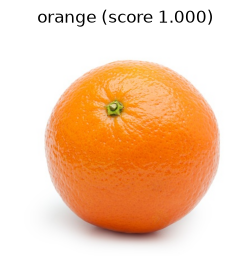

1d426253b7_kaggle_train_orange_72.jpg: predicted orange; model score 1.000


In [10]:
import src.inference
print(inspect.getsource(src.inference))
photo = sorted((SPLITS / 'test' / 'orange').glob('*.jpg'))[2]
with Image.open(photo) as img:
    label, score = predict_pil(model, idx_to_class, transform, img)
    plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis('off')
    plt.title(f'{label} (score {score:.3f})'); plt.show()
print(f'{photo.name}: predicted {label}; model score {score:.3f}')